<a href="https://colab.research.google.com/github/ishitajain16/EV-range-prediction/blob/main/EV_range_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q xgboost shap

In [2]:
import os, glob, json, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import shap
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (9, 4.5)
RANDOM_STATE = 42          # fixed seed → same results every run
print("All libraries imported ✅")

All libraries imported ✅


**UPLOADING DATASET**

In [3]:
import urllib.request

GITHUB_USER = "ishitajain16"
REPO = "EV-range-prediction"
BRANCH = "main"

PROJECT_DIR = "/content/EV_range_prediction" if os.path.exists("/content") else "./EV_range_prediction"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUT_DIR = os.path.join(PROJECT_DIR, "outputs")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

zip_path = os.path.join(PROJECT_DIR, "ev_range_delhi_data.zip")
local_copy = "data/ev_range_delhi_data.zip"
if os.path.exists(local_copy):
    zip_path = local_copy
elif not os.path.exists(zip_path):
    url = f"https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/{BRANCH}/data/ev_range_delhi_data.zip"
    print("Downloading dataset from GitHub...")
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path) as z:
    for member in z.namelist():
        if member.endswith("/"):
            continue
        target = os.path.join(DATA_DIR, os.path.basename(member))
        if not os.path.exists(target):
            with z.open(member) as src, open(target, "wb") as dst:
                dst.write(src.read())

print("Dataset ready ✅")
print("Files in data folder:", sorted(os.listdir(DATA_DIR)))

Dataset ready ✅
Files in data folder: ['ac_power_vs_temperature.csv', 'delhi_trip_log_template.csv', 'midc_drive_cycle.csv', 'ved_trip_summary.csv', 'ved_trips_1hz.parquet', 'vehicle_config_template.csv']


**UNDERSTANDING DATA**

In [4]:
trips_raw = pd.read_csv(os.path.join(DATA_DIR, "ved_trip_summary.csv"), parse_dates=["start_datetime"])
print("Trip summary shape (rows, columns):", trips_raw.shape)
trips_raw.head()

Trip summary shape (rows, columns): (3687, 33)


,VehId,Trip,EngineType,start_datetime,month,hour,duration_min,distance_km,mean_speed_kmh,mean_moving_speed_kmh,...,batt_energy_wh,wh_per_km,soc_start_pct,soc_end_pct,engine_on_pct,n_samples,soc_drop_pct,electric_only,valid_for_energy_model,vehicle_mass_kg
0,9,1767,PHEV,2018-03-07 20:21:25,3,20,4.340,3.011,41.632,43.286,...,785.352,260.793,54.118,44.314,0.0,389,9.804,True,True,1814.0
1,9,2157,PHEV,2018-06-29 20:18:31,6,20,3.743,3.015,48.321,48.375,...,352.825,117.034,59.216,55.686,0.0,332,3.529,True,True,1814.0
2,9,2267,PHEV,2018-07-29 20:33:14,7,20,2.332,2.395,61.620,61.338,...,381.691,159.396,57.255,56.078,0.0,209,1.176,True,True,1814.0
3,10,1561,EV,2017-11-02 21:27:13,11,21,7.538,2.376,18.914,25.451,...,675.951,284.459,71.707,66.463,0.0,534,5.244,True,True,1588.0
4,10,1567,EV,2017-11-04 12:57:54,11,12,6.145,1.423,13.891,23.091,...,511.222,359.352,71.098,67.561,0.0,367,3.537,True,True,1588.0


In [5]:
traces = pd.read_parquet(os.path.join(DATA_DIR, "ved_trips_1hz.parquet"))
print("Speed traces shape:", traces.shape)
traces.head()

Speed traces shape: (1172751, 8)


,VehId,Trip,t_s,speed_kmh,oat_c,batt_power_w,ac_power_w,heater_power_w
0,9,1767,0,29.799999,3.5,41060.300781,0.0,NaN
1,9,1767,1,35.000000,3.5,49302.000000,0.0,NaN
2,9,1767,2,43.200001,3.5,55362.000000,0.0,NaN
3,9,1767,3,45.799999,3.5,55387.699219,0.0,NaN
4,9,1767,4,53.200001,3.5,52075.199219,0.0,NaN


In [6]:
ac_table = pd.read_csv(os.path.join(DATA_DIR, "ac_power_vs_temperature.csv"))
print("AC table shape:", ac_table.shape)
ac_table.head()

AC table shape: (31, 8)


,oat_low_c,oat_high_c,n_samples,mean_ac_power_w,median_ac_power_w,p90_ac_power_w,ac_on_fraction,mean_heater_power_w
0,-22,-20,1482,0.000,0.0,0.0,0.000,NaN
1,-20,-18,2275,0.000,0.0,0.0,0.000,NaN
2,-18,-16,8053,426.370,0.0,0.0,0.071,NaN
3,-16,-14,14815,121.048,0.0,0.0,0.022,3690.393
4,-14,-12,20671,179.574,0.0,0.0,0.036,3518.563


MIDC shape: (1181, 5)


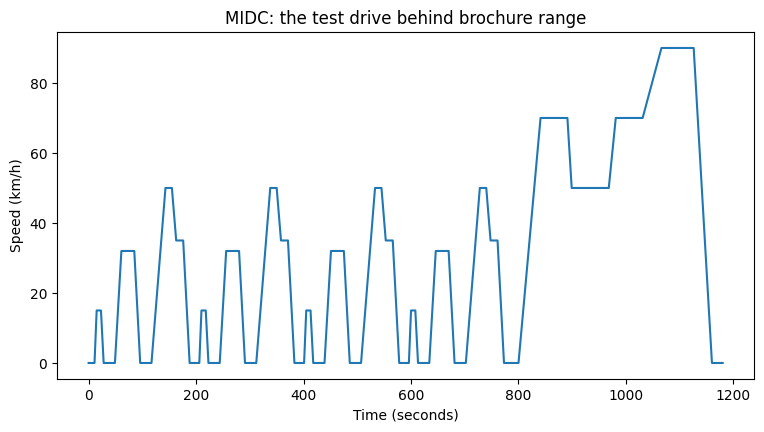

In [7]:
midc = pd.read_csv(os.path.join(DATA_DIR, "midc_drive_cycle.csv"))
print("MIDC shape:", midc.shape)
plt.plot(midc.time_s, midc.speed_kmh)
plt.xlabel("Time (seconds)"); plt.ylabel("Speed (km/h)"); plt.title("MIDC: the test drive behind brochure range")
plt.show()

In [8]:
trips_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3687 entries, 0 to 3686
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   VehId                   3687 non-null   int64         
 1   Trip                    3687 non-null   int64         
 2   EngineType              3687 non-null   object        
 3   start_datetime          3687 non-null   datetime64[ns]
 4   month                   3687 non-null   int64         
 5   hour                    3687 non-null   int64         
 6   duration_min            3687 non-null   float64       
 7   distance_km             3687 non-null   float64       
 8   mean_speed_kmh          3687 non-null   float64       
 9   mean_moving_speed_kmh   3687 non-null   float64       
 10  std_speed_kmh           3687 non-null   float64       
 11  max_speed_kmh           3687 non-null   float64       
 12  pct_time_idle           3687 non-null   float64 

In [9]:
trips_raw[["distance_km", "duration_min", "mean_speed_kmh", "oat_mean_c", "wh_per_km"]].describe().round(1)

,distance_km,duration_min,mean_speed_kmh,oat_mean_c,wh_per_km
count,3687.0,3687.0,3687.0,3685.0,3687.0
mean,6.1,10.6,38.3,12.3,119.8
std,4.0,8.6,12.7,11.9,95.9
min,1.0,2.0,4.5,-20.8,-239.3
25%,3.0,5.1,30.2,3.1,26.1
50%,5.4,8.7,37.0,11.3,135.2
75%,7.7,12.6,44.6,22.7,181.1
max,36.8,95.1,104.4,36.9,794.3


In [10]:
missing = trips_raw.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0])

Columns with missing values:
mean_pos_accel_ms2    1
oat_mean_c            2
oat_max_c             2
soc_start_pct         2
soc_end_pct           2
soc_drop_pct          2
dtype: int64


**DATA PRE-PROCESSING**

Trips before cleaning: 3687
Trips after keeping valid ones: 2131
Trips after removing missing values: 2131
Number of different vehicles: 26


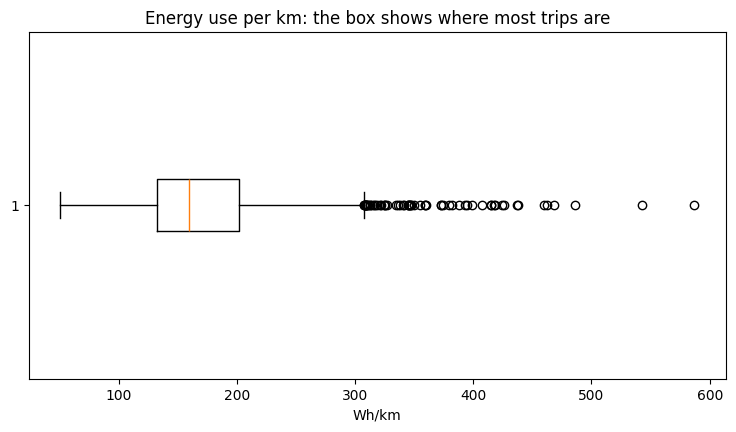

In [11]:
trips = trips_raw[trips_raw["valid_for_energy_model"] == True].copy()
print("Trips before cleaning:", len(trips_raw))
print("Trips after keeping valid ones:", len(trips))

needed = ["distance_km", "duration_min", "mean_speed_kmh", "mean_moving_speed_kmh", "std_speed_kmh",
          "max_speed_kmh", "pct_time_idle", "pct_time_below_20kmh", "stops_per_km", "rpa_ms2",
          "oat_mean_c", "vehicle_mass_kg", "wh_per_km"]
trips = trips.dropna(subset=needed).reset_index(drop=True)
print("Trips after removing missing values:", len(trips))
print("Number of different vehicles:", trips.VehId.nunique())

plt.boxplot(trips.wh_per_km, vert=False)
plt.xlabel("Wh/km"); plt.title("Energy use per km: the box shows where most trips are")
plt.show()

Downloaded ✅
Rows: 35,064 | coldest 3.2°C | hottest 46.0°C


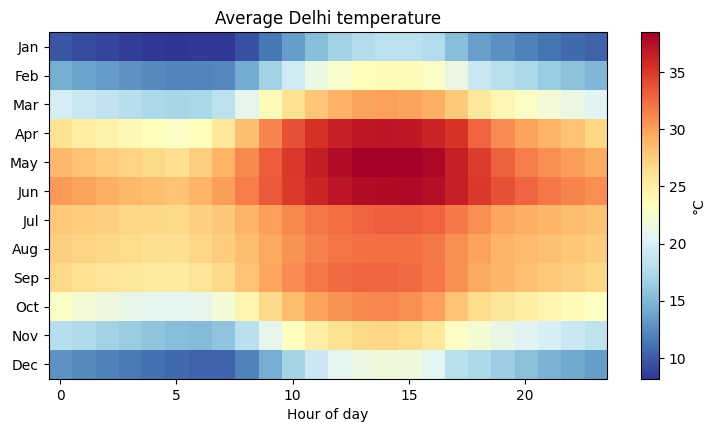

In [12]:
import requests
weather_path = os.path.join(DATA_DIR, "delhi_weather_hourly.csv")

if not os.path.exists(weather_path):
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": 28.61, "longitude": 77.21,
        "start_date": "2022-01-01", "end_date": "2025-12-31",
        "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m",
        "timezone": "Asia/Kolkata"}, timeout=120)
    response.raise_for_status()
    pd.DataFrame(response.json()["hourly"]).to_csv(weather_path, index=False)
    print("Downloaded ✅")

weather = pd.read_csv(weather_path, parse_dates=["time"])
weather["month"] = weather.time.dt.month
weather["hour"] = weather.time.dt.hour
delhi_temp = weather.pivot_table(index="month", columns="hour", values="temperature_2m", aggfunc="mean")

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
print(f"Rows: {len(weather):,} | coldest {weather.temperature_2m.min():.1f}°C | hottest {weather.temperature_2m.max():.1f}°C")
plt.imshow(delhi_temp, aspect="auto", cmap="RdYlBu_r")
plt.colorbar(label="°C"); plt.yticks(range(12), MONTHS); plt.xlabel("Hour of day")
plt.title("Average Delhi temperature"); plt.show()

**EXPLORATORY DATA ANALYSIS**

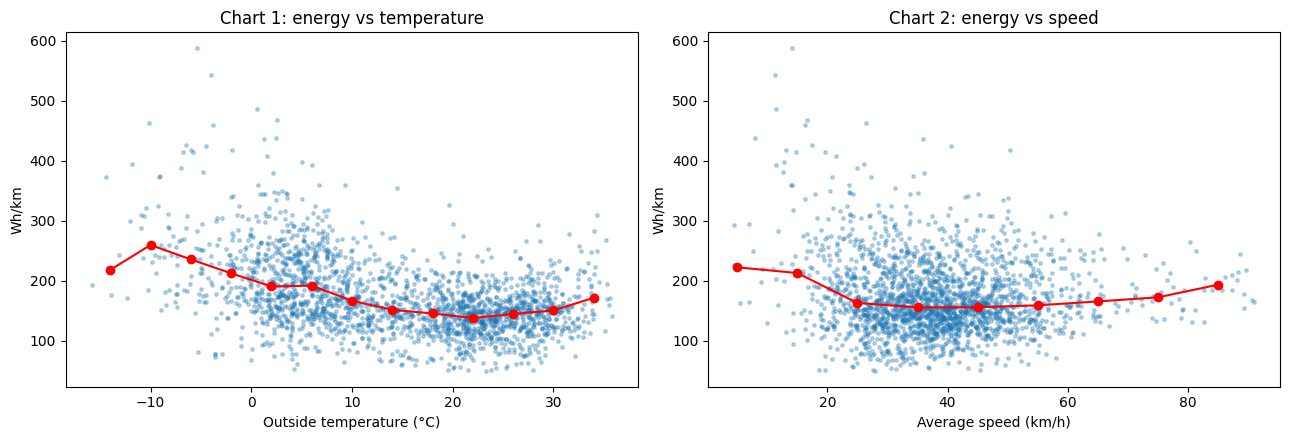

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].scatter(trips.oat_mean_c, trips.wh_per_km, s=6, alpha=0.3)
med = trips.groupby(pd.cut(trips.oat_mean_c, np.arange(-20, 40, 4)), observed=True).wh_per_km.median()
ax[0].plot([b.mid for b in med.index], med.values, "r-o")
ax[0].set(xlabel="Outside temperature (°C)", ylabel="Wh/km", title="Chart 1: energy vs temperature")

ax[1].scatter(trips.mean_speed_kmh, trips.wh_per_km, s=6, alpha=0.3)
med = trips.groupby(pd.cut(trips.mean_speed_kmh, np.arange(0, 100, 10)), observed=True).wh_per_km.median()
ax[1].plot([b.mid for b in med.index], med.values, "r-o")
ax[1].set(xlabel="Average speed (km/h)", ylabel="Wh/km", title="Chart 2: energy vs speed")
plt.tight_layout(); plt.show()

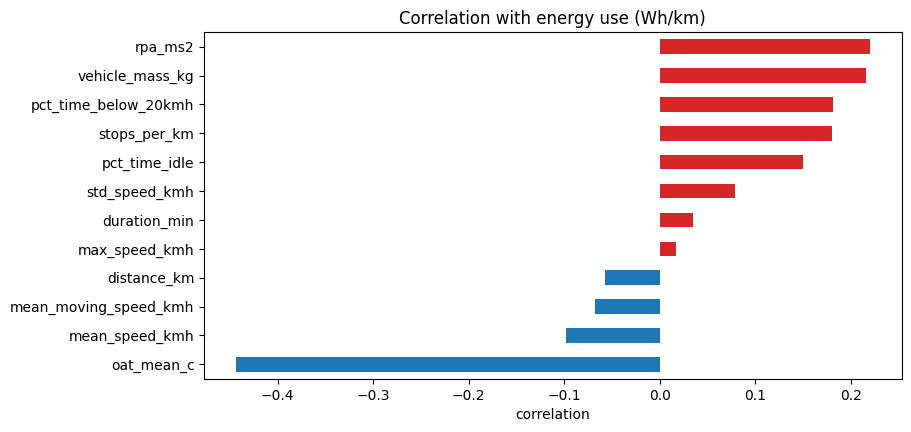

In [14]:
corr = trips[needed].corr()["wh_per_km"].drop("wh_per_km").sort_values()
corr.plot(kind="barh", color=["tab:blue" if c < 0 else "tab:red" for c in corr])
plt.title("Correlation with energy use (Wh/km)"); plt.xlabel("correlation"); plt.show()

AC rule:     222 W + 51.8 W for every °C above 18°C
Heater rule: 72.7 W for every °C below 16°C
   5°C  →   1021 W
  15°C  →    294 W
  25°C  →    584 W
  35°C  →   1102 W
  40°C  →   1361 W
  45°C  →   1620 W


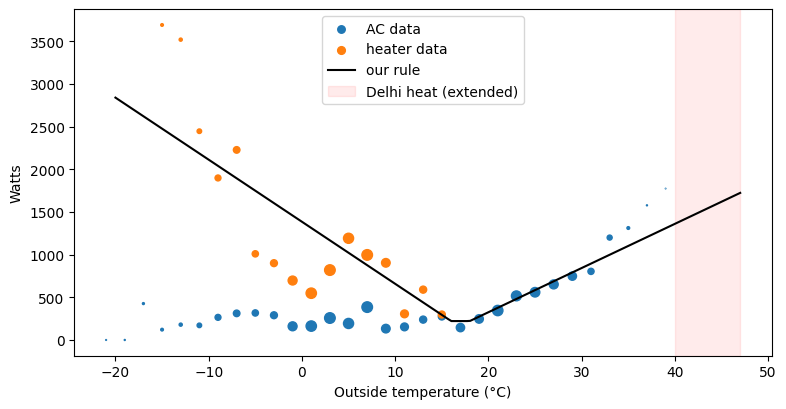

In [15]:
ac = ac_table.assign(T=(ac_table.oat_low_c + ac_table.oat_high_c) / 2)
weights = np.sqrt(ac.n_samples)

def ac_error(p):
    return (p[0] + p[1] * np.maximum(0, ac["T"] - 18) - ac.mean_ac_power_w) * weights
AC_C0, AC_K = least_squares(ac_error, [200, 60]).x

heat = ac.dropna(subset=["mean_heater_power_w"]).query("T < 16")
HEAT_K = least_squares(lambda p: (p[0] * np.maximum(0, 16 - heat["T"]) - heat.mean_heater_power_w)
                       * np.sqrt(heat.n_samples), [100]).x[0]

def climate_power_w(T):
    """AC + heater power (watts) at outside temperature T (°C)."""
    T = np.asarray(T, dtype=float)
    return AC_C0 + AC_K * np.maximum(0, T - 18) + HEAT_K * np.maximum(0, 16 - T)

print(f"AC rule:     {AC_C0:.0f} W + {AC_K:.1f} W for every °C above 18°C")
print(f"Heater rule: {HEAT_K:.1f} W for every °C below 16°C")
for T in [5, 15, 25, 35, 40, 45]:
    print(f"  {T:>2}°C  →  {climate_power_w(T):5.0f} W")

T_line = np.linspace(-20, 47, 200)
plt.scatter(ac["T"], ac.mean_ac_power_w, s=ac.n_samples / 4000, label="AC data")
plt.scatter(heat["T"], heat.mean_heater_power_w, s=heat.n_samples / 4000, label="heater data")
plt.plot(T_line, climate_power_w(T_line), "k-", label="our rule")
plt.axvspan(40, 47, color="red", alpha=0.08, label="Delhi heat (extended)")
plt.xlabel("Outside temperature (°C)"); plt.ylabel("Watts"); plt.legend(); plt.show()

**TRAIN-TEST SPLITING**

In [16]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(trips, groups=trips.VehId))
trips["split"] = "train"
trips.loc[test_idx, "split"] = "test"
print(trips.groupby("split").agg(trips=("Trip", "size"), vehicles=("VehId", "nunique")))

       trips  vehicles
split                 
test     219         7
train   1912        19


**BUILDING PHYSICS MODEL**

In [17]:
DRIVER_KG = 80

tr = traces.merge(trips[["VehId", "Trip", "vehicle_mass_kg", "split"]], on=["VehId", "Trip"])
tr = tr.sort_values(["VehId", "Trip", "t_s"]).reset_index(drop=True)
tr["v"] = tr.speed_kmh / 3.6
tr["v_smooth"] = tr.groupby(["VehId", "Trip"]).v.transform(lambda s: s.rolling(3, center=True, min_periods=1).mean())
tr["a"] = tr.groupby(["VehId", "Trip"]).v_smooth.diff().fillna(0).clip(-4, 4)
tr["rho"] = 101325 / (287.05 * (tr.oat_c + 273.15))
tr["m"] = tr.vehicle_mass_kg + DRIVER_KG
tr["climate_w"] = climate_power_w(tr.oat_c)
trip_index = trips.set_index(["VehId", "Trip"]).index
tr["k"] = trip_index.get_indexer(pd.MultiIndex.from_frame(tr[["VehId", "Trip"]]))

def physics_energy_wh(params, df, n_trips):
    """Total battery energy (Wh) of every trip. params = [eta_drive, eta_regen, Crr, CdA, aux_w]."""
    eta_drive, eta_regen, crr, cda, aux_w = params
    force = (df.m.values * 9.81 * crr
             + 0.5 * df.rho.values * cda * df.v.values ** 2
             + 1.05 * df.m.values * df.a.values)
    wheel_power = np.where(df.v.values <= 0.05, 0.0, force * df.v.values)
    battery_power = np.where(wheel_power >= 0, wheel_power / eta_drive, wheel_power * eta_regen)
    battery_power = battery_power + aux_w + df.climate_w.values
    return np.bincount(df.k.values, weights=battery_power, minlength=n_trips) / 3600.0

print("Physics model ready ✅")

Physics model ready ✅


In [18]:
N = len(trips)
distance = trips.distance_km.values
actual = trips.wh_per_km.values
is_train = (trips.split == "train").values
tr_train = tr[tr.split == "train"]

def calibration_error(params):
    predicted = physics_energy_wh(params, tr_train, N)[is_train] / distance[is_train]
    return (predicted - actual[is_train]) / actual[is_train]

start = [0.85, 0.60, 0.010, 0.70, 300]
lower = [0.70, 0.30, 0.006, 0.45, 0]
upper = [0.95, 0.90, 0.015, 1.10, 1500]
fit = least_squares(calibration_error, start, bounds=(lower, upper), loss="soft_l1")
PHYS = dict(zip(["eta_drive", "eta_regen", "Crr", "CdA", "aux_w"], [round(float(x), 4) for x in fit.x]))
print("Calibrated physics values:", PHYS)

trips["physics_wh_per_km"] = physics_energy_wh(fit.x, tr, N) / distance
for s in ["train", "test"]:
    d = trips[trips.split == s]
    print(f"Physics model error on {s}: {mean_absolute_error(d.wh_per_km, d.physics_wh_per_km):.1f} Wh/km")

Calibrated physics values: {'eta_drive': 0.8945, 'eta_regen': 0.9, 'Crr': 0.0126, 'CdA': 0.5806, 'aux_w': 0.0}
Physics model error on train: 39.8 Wh/km
Physics model error on test: 52.2 Wh/km


In [19]:
FEATURES = ["distance_km", "duration_min", "mean_speed_kmh", "mean_moving_speed_kmh", "std_speed_kmh",
            "max_speed_kmh", "pct_time_idle", "pct_time_below_20kmh", "stops_per_km", "rpa_ms2", "oat_mean_c"]
PURE_FEATURES = FEATURES + ["vehicle_mass_kg"]

trips["log_ratio"] = np.log(trips.wh_per_km / trips.physics_wh_per_km)
train = trips[trips.split == "train"].reset_index(drop=True)
test = trips[trips.split == "test"].reset_index(drop=True)

X_train_pure, X_test_pure = train[PURE_FEATURES], test[PURE_FEATURES]
X_train_hyb, X_test_hyb = train[FEATURES], test[FEATURES]
y_train, y_test = train.wh_per_km, test.wh_per_km
r_train = train.log_ratio
groups_train = train.VehId
print("X_train_pure:", X_train_pure.shape, "| X_test_pure:", X_test_pure.shape)
X_train_pure.head()

X_train_pure: (1912, 12) | X_test_pure: (219, 12)


,distance_km,duration_min,mean_speed_kmh,mean_moving_speed_kmh,std_speed_kmh,max_speed_kmh,pct_time_idle,pct_time_below_20kmh,stops_per_km,rpa_ms2,oat_mean_c,vehicle_mass_kg
0,2.376,7.538,18.914,25.451,15.884,53.05,23.856,53.416,3.787,0.371,4.754,1588.0
1,1.423,6.145,13.891,23.091,13.809,41.83,38.731,62.408,4.920,0.300,9.323,1588.0
2,1.440,5.052,17.101,31.070,17.446,49.09,42.956,57.803,3.473,0.234,9.606,1588.0
3,2.080,6.283,19.862,27.055,16.030,58.74,24.960,51.432,4.327,0.441,14.164,1588.0
4,1.071,3.887,16.540,24.376,13.841,42.92,31.904,56.818,3.733,0.313,9.936,1588.0


In [20]:
results = []

def score(model_name, stage, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    row = {"model": model_name, "stage": stage,
           "MAE": mean_absolute_error(y_true, y_pred),
           "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
           "MAPE_%": np.mean(np.abs(y_pred - y_true) / y_true) * 100,
           "R2": r2_score(y_true, y_pred)}
    results.append(row)
    print(f"{model_name:<32} [{stage}]  MAE={row['MAE']:.1f}  RMSE={row['RMSE']:.1f}  MAPE={row['MAPE_%']:.1f}%  R²={row['R2']:.3f}")
    return y_pred

def hybrid_to_whkm(log_ratio_pred, data):
    """Turn a hybrid model's correction back into Wh/km."""
    return data.physics_wh_per_km.values * np.exp(log_ratio_pred)

In [21]:
pred_physics = score("1. Physics only", "no tuning needed", y_test, test.physics_wh_per_km)

1. Physics only                  [no tuning needed]  MAE=52.2  RMSE=71.6  MAPE=23.9%  R²=-0.099


**LINEAR REGRESSION TRAINING**

In [22]:
lr = make_pipeline(StandardScaler(), LinearRegression())
lr.fit(X_train_pure, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

In [23]:
pred_lr = score("2. Linear Regression", "default", y_test, lr.predict(X_test_pure))

2. Linear Regression             [default]  MAE=38.4  RMSE=53.9  MAPE=19.5%  R²=0.378


**RANDOM FOREST TRAINING**

In [24]:
rf_default = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
rf_default.fit(X_train_pure, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [25]:
pred_rf_default = score("3. Random Forest", "default", y_test, rf_default.predict(X_test_pure))

3. Random Forest                 [default]  MAE=33.2  RMSE=46.2  MAPE=17.1%  R²=0.543


**XGBOOST TRAINING**

In [26]:
xgb_default = xgb.XGBRegressor(random_state=RANDOM_STATE)
xgb_default.fit(X_train_pure, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [27]:
pred_xgb_default = score("4. XGBoost", "default", y_test, xgb_default.predict(X_test_pure))

4. XGBoost                       [default]  MAE=35.9  RMSE=48.9  MAPE=18.6%  R²=0.488


**HYBRID PHYSICS + RANDOM FOREST TRANINIG**

In [28]:
hrf_default = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
hrf_default.fit(X_train_hyb, r_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [29]:
pred_hrf_default = score("5. Hybrid Physics + RF", "default", y_test,
                         hybrid_to_whkm(hrf_default.predict(X_test_hyb), test))

5. Hybrid Physics + RF           [default]  MAE=39.3  RMSE=53.7  MAPE=19.6%  R²=0.381


**HYBRID PHYSICS + XGBOOST TRAINING**

In [30]:
hxgb_default = xgb.XGBRegressor(random_state=RANDOM_STATE)
hxgb_default.fit(X_train_hyb, r_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [31]:
pred_hxgb_default = score("6. Hybrid Physics + XGBoost", "default", y_test,
                          hybrid_to_whkm(hxgb_default.predict(X_test_hyb), test))

6. Hybrid Physics + XGBoost      [default]  MAE=39.9  RMSE=55.1  MAPE=20.0%  R²=0.348


**RESULTS**

In [32]:
before = pd.DataFrame(results).round(3)
before

,model,stage,MAE,RMSE,MAPE_%,R2
0,1. Physics only,no tuning needed,52.166,71.585,23.922,-0.099
1,2. Linear Regression,default,38.353,53.874,19.468,0.378
2,3. Random Forest,default,33.152,46.167,17.098,0.543
3,4. XGBoost,default,35.912,48.886,18.594,0.488
4,5. Hybrid Physics + RF,default,39.252,53.744,19.601,0.381
5,6. Hybrid Physics + XGBoost,default,39.936,55.139,19.991,0.348


**HYPERPARAMETER TUNINIG**

In [33]:
cv_by_vehicle = GroupKFold(n_splits=5)
N_ITER = 30

In [34]:
rf_space = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [None, 4, 6, 8, 12, 16],
    "min_samples_leaf": [1, 2, 4, 8, 16],
    "max_features": [0.3, 0.5, 0.7, 1.0],
}

In [35]:
xgb_space = {
    "n_estimators": [200, 400, 600, 900, 1200],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5, 6, 8],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10, 20],
    "reg_lambda": [0.5, 1, 2, 5, 10],
    "gamma": [0, 0.05, 0.1, 0.3],
}

In [36]:
def tune(base_model, space, X, y, name):
    t0 = time.time()
    search = RandomizedSearchCV(base_model, space, n_iter=N_ITER, cv=cv_by_vehicle,
                                scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X, y, groups=groups_train)
    print(f"{name}: best settings found in {time.time() - t0:.0f} s")
    print("   ", search.best_params_)
    return search

1. RANDOM FOREST

In [37]:
rf_search = tune(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), rf_space, X_train_pure, y_train, "Random Forest")
rf_tuned = rf_search.best_estimator_

Random Forest: best settings found in 535 s
    {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None}


In [38]:
pred_rf_tuned = score("3. Random Forest", "tuned", y_test, rf_tuned.predict(X_test_pure))

3. Random Forest                 [tuned]  MAE=33.6  RMSE=48.2  MAPE=16.9%  R²=0.502


2. XGBOOST

In [39]:
xgb_search = tune(xgb.XGBRegressor(random_state=RANDOM_STATE), xgb_space, X_train_pure, y_train, "XGBoost")
xgb_tuned = xgb_search.best_estimator_

XGBoost: best settings found in 89 s
    {'subsample': 0.6, 'reg_lambda': 1, 'n_estimators': 900, 'min_child_weight': 20, 'max_depth': 3, 'learning_rate': 0.02, 'gamma': 0.1, 'colsample_bytree': 1.0}


In [40]:
pred_xgb_tuned = score("4. XGBoost", "tuned", y_test, xgb_tuned.predict(X_test_pure))

4. XGBoost                       [tuned]  MAE=32.6  RMSE=44.7  MAPE=16.8%  R²=0.571


3. HYBRID + RANDOM FOREST

In [41]:
hrf_search = tune(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), rf_space, X_train_hyb, r_train, "Hybrid + RF")
hrf_tuned = hrf_search.best_estimator_

Hybrid + RF: best settings found in 531 s
    {'n_estimators': 300, 'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 4}


In [42]:
pred_hrf_tuned = score("5. Hybrid Physics + RF", "tuned", y_test, hybrid_to_whkm(hrf_tuned.predict(X_test_hyb), test))

5. Hybrid Physics + RF           [tuned]  MAE=40.0  RMSE=56.3  MAPE=19.5%  R²=0.320


4. HYBRID + XGBOOST

In [43]:
hxgb_search = tune(xgb.XGBRegressor(random_state=RANDOM_STATE), xgb_space, X_train_hyb, r_train, "Hybrid + XGBoost")
hxgb_tuned = hxgb_search.best_estimator_

Hybrid + XGBoost: best settings found in 62 s
    {'subsample': 0.9, 'reg_lambda': 0.5, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.1, 'gamma': 0.3, 'colsample_bytree': 0.6}


In [44]:
pred_hxgb_tuned = score("6. Hybrid Physics + XGBoost", "tuned", y_test, hybrid_to_whkm(hxgb_tuned.predict(X_test_hyb), test))

6. Hybrid Physics + XGBoost      [tuned]  MAE=38.5  RMSE=53.6  MAPE=19.0%  R²=0.384


**RESULTS AFTER TUNINIG**

In [45]:
after = pd.DataFrame(results)
after = after[after.stage == "tuned"].drop(columns="stage")
after = after.sort_values("MAE").reset_index(drop=True)
after.index = after.index + 1                      # rank starts at 1
after.index.name = "rank"
print("📊 Results AFTER hyperparameter tuning (test cars, best at the top)")
display(after.round(3))

📊 Results AFTER hyperparameter tuning (test cars, best at the top)


,model,MAE,RMSE,MAPE_%,R2
rank,,,,,
1,4. XGBoost,32.555,44.731,16.785,0.571
2,3. Random Forest,33.599,48.198,16.874,0.502
3,6. Hybrid Physics + XGBoost,38.468,53.586,19.022,0.384
4,5. Hybrid Physics + RF,39.996,56.298,19.475,0.320


In [46]:
best_settings = pd.DataFrame({
    "3. Random Forest": rf_search.best_params_,
    "4. XGBoost": xgb_search.best_params_,
    "5. Hybrid Physics + RF": hrf_search.best_params_,
    "6. Hybrid Physics + XGBoost": hxgb_search.best_params_,
}).T
best_settings["CV MAE during tuning"] = [
    -rf_search.best_score_, -xgb_search.best_score_, -hrf_search.best_score_, -hxgb_search.best_score_
]

In [47]:
print("\n⚙️ Best hyperparameters found by RandomizedSearchCV")
display(best_settings.fillna("—"))


⚙️ Best hyperparameters found by RandomizedSearchCV


,n_estimators,min_samples_leaf,max_features,max_depth,subsample,reg_lambda,min_child_weight,learning_rate,gamma,colsample_bytree,CV MAE during tuning
3. Random Forest,200.0,1.0,0.3,—,—,—,—,—,—,—,39.461838
4. XGBoost,900.0,—,—,3.0,0.6,1.0,20.0,0.02,0.1,1.0,37.875851
5. Hybrid Physics + RF,300.0,8.0,0.3,4.0,—,—,—,—,—,—,0.217233
6. Hybrid Physics + XGBoost,200.0,—,—,8.0,0.9,0.5,3.0,0.1,0.3,0.6,0.217131


**COMPARISTION AFTER TUNINIG**

In [48]:
res = pd.DataFrame(results)
res = res[res.stage.isin(["no tuning needed", "default", "tuned"])]
res["when"] = res.stage.replace({"no tuning needed": "default"})
pv = res.pivot_table(index="model", columns="when", values=["MAE", "RMSE", "R2"])
compare = pd.DataFrame({
    "MAE before tuning": pv[("MAE", "default")],
    "MAE after tuning": pv[("MAE", "tuned")],
    "RMSE before": pv[("RMSE", "default")],
    "RMSE after": pv[("RMSE", "tuned")],
    "R² before": pv[("R2", "default")],
    "R² after": pv[("R2", "tuned")],
})
compare["MAE change %"] = (compare["MAE after tuning"] / compare["MAE before tuning"] - 1) * 100
compare.round(2).fillna("not tuned")

,MAE before tuning,MAE after tuning,RMSE before,RMSE after,R² before,R² after,MAE change %
model,,,,,,,
1. Physics only,52.17,not tuned,71.59,not tuned,-0.10,not tuned,not tuned
2. Linear Regression,38.35,not tuned,53.87,not tuned,0.38,not tuned,not tuned
3. Random Forest,33.15,33.6,46.17,48.2,0.54,0.5,1.35
4. XGBoost,35.91,32.55,48.89,44.73,0.49,0.57,-9.35
5. Hybrid Physics + RF,39.25,40.0,53.74,56.3,0.38,0.32,1.9
6. Hybrid Physics + XGBoost,39.94,38.47,55.14,53.59,0.35,0.38,-3.68


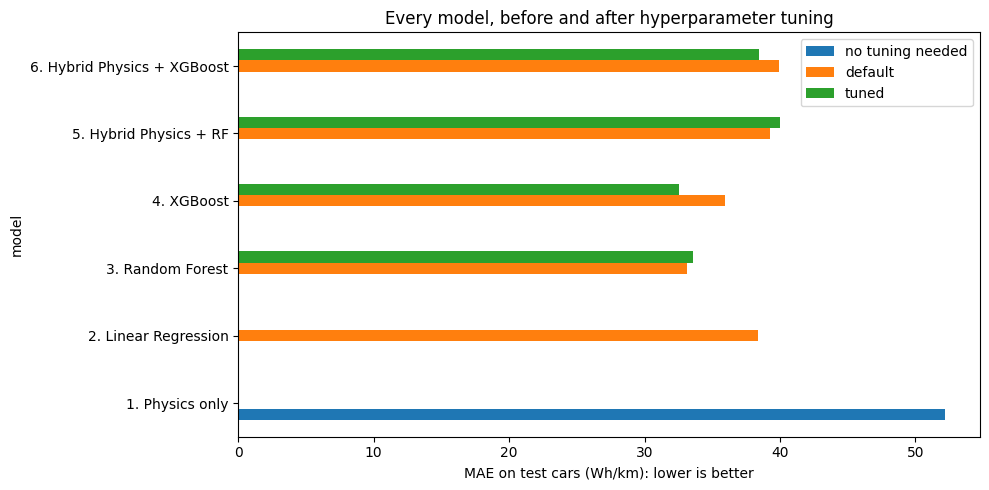

In [49]:
plot_df = res.pivot_table(index="model", columns="stage", values="MAE")
plot_df = plot_df[[c for c in ["no tuning needed", "default", "tuned"] if c in plot_df]]
plot_df.plot(kind="barh", figsize=(10, 5))
plt.xlabel("MAE on test cars (Wh/km): lower is better")
plt.title("Every model, before and after hyperparameter tuning")
plt.legend(title=""); plt.tight_layout(); plt.show()

**5-FOLD CROSS-VALIDATION**

In [50]:
def make_models():
    return {
        "2. Linear Regression":          ("pure", make_pipeline(StandardScaler(), LinearRegression())),
        "3. Random Forest (default)":     ("pure", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
        "3. Random Forest (tuned)":       ("pure", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)),
        "4. XGBoost (default)":           ("pure", xgb.XGBRegressor(random_state=RANDOM_STATE)),
        "4. XGBoost (tuned)":             ("pure", xgb.XGBRegressor(random_state=RANDOM_STATE, **xgb_search.best_params_)),
        "5. Hybrid + RF (default)":       ("hyb", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
        "5. Hybrid + RF (tuned)":         ("hyb", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **hrf_search.best_params_)),
        "6. Hybrid + XGBoost (default)":  ("hyb", xgb.XGBRegressor(random_state=RANDOM_STATE)),
        "6. Hybrid + XGBoost (tuned)":    ("hyb", xgb.XGBRegressor(random_state=RANDOM_STATE, **hxgb_search.best_params_)),
    }

cv_rows = []
for fold, (i_tr, i_te) in enumerate(GroupKFold(n_splits=5).split(trips, groups=trips.VehId)):
    a, b = trips.iloc[i_tr], trips.iloc[i_te]
    cv_rows.append({"fold": fold, "model": "1. Physics only", "MAE": mean_absolute_error(b.wh_per_km, b.physics_wh_per_km)})
    for name, (kind, model) in make_models().items():
        if kind == "pure":
            model.fit(a[PURE_FEATURES], a.wh_per_km)
            p = model.predict(b[PURE_FEATURES])
        else:
            model.fit(a[FEATURES], a.log_ratio)
            p = hybrid_to_whkm(model.predict(b[FEATURES]), b)
        cv_rows.append({"fold": fold, "model": name, "MAE": mean_absolute_error(b.wh_per_km, p)})

cv_table = pd.DataFrame(cv_rows).groupby("model").MAE.agg(["mean", "std"]).round(2).sort_values("mean")
cv_table.columns = ["MAE mean (Wh/km)", "MAE spread (±)"]
print("Ranking (best at the top):")
print(cv_table.to_string())

cv_mean = cv_table["MAE mean (Wh/km)"]
cv_compare = pd.DataFrame([{
    "model": base,
    "MAE before tuning": cv_mean[f"{base} (default)"],
    "MAE after tuning": cv_mean[f"{base} (tuned)"],
} for base in ["3. Random Forest", "4. XGBoost", "5. Hybrid + RF", "6. Hybrid + XGBoost"]]).set_index("model")
cv_compare["MAE change %"] = (cv_compare["MAE after tuning"] / cv_compare["MAE before tuning"] - 1) * 100
cv_compare.round(2)

Ranking (best at the top):
                               MAE mean (Wh/km)  MAE spread (±)
model                                                          
5. Hybrid + RF (tuned)                    35.85            5.14
6. Hybrid + XGBoost (tuned)               36.36            4.40
5. Hybrid + RF (default)                  37.08            4.46
4. XGBoost (tuned)                        37.89            2.79
2. Linear Regression                      38.86            3.14
3. Random Forest (tuned)                  38.92            4.23
3. Random Forest (default)                39.68            3.93
6. Hybrid + XGBoost (default)             39.91            3.27
1. Physics only                           41.12            9.01
4. XGBoost (default)                      41.43            3.38


,MAE before tuning,MAE after tuning,MAE change %
model,,,
3. Random Forest,39.68,38.92,-1.92
4. XGBoost,41.43,37.89,-8.54
5. Hybrid + RF,37.08,35.85,-3.32
6. Hybrid + XGBoost,39.91,36.36,-8.90


**MODEL SELECTION**

Final model: Hybrid Physics + XGBoost (tuned)


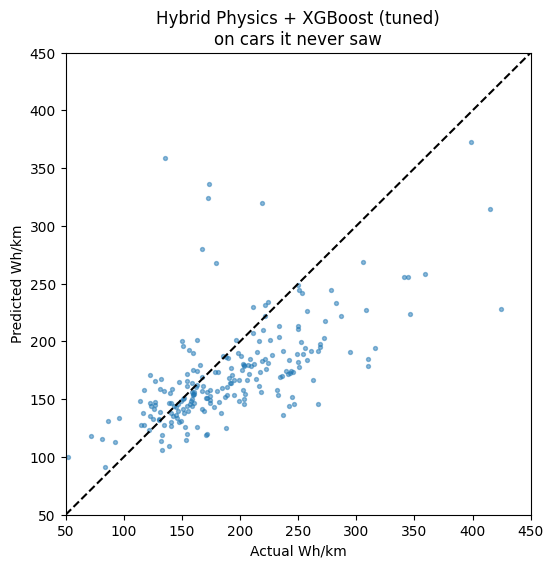

In [51]:
if -hxgb_search.best_score_ <= -hrf_search.best_score_:
    FINAL_NAME, FINAL_MODEL = "Hybrid Physics + XGBoost (tuned)", hxgb_tuned
else:
    FINAL_NAME, FINAL_MODEL = "Hybrid Physics + RF (tuned)", hrf_tuned
print("Final model:", FINAL_NAME)

final_pred = hybrid_to_whkm(FINAL_MODEL.predict(X_test_hyb), test)
plt.figure(figsize=(6, 6))
plt.scatter(test.wh_per_km, final_pred, s=8, alpha=0.5)
plt.plot([50, 450], [50, 450], "k--"); plt.xlim(50, 450); plt.ylim(50, 450)
plt.xlabel("Actual Wh/km"); plt.ylabel("Predicted Wh/km"); plt.title(f"{FINAL_NAME}\non cars it never saw")
plt.show()

**SHAP**

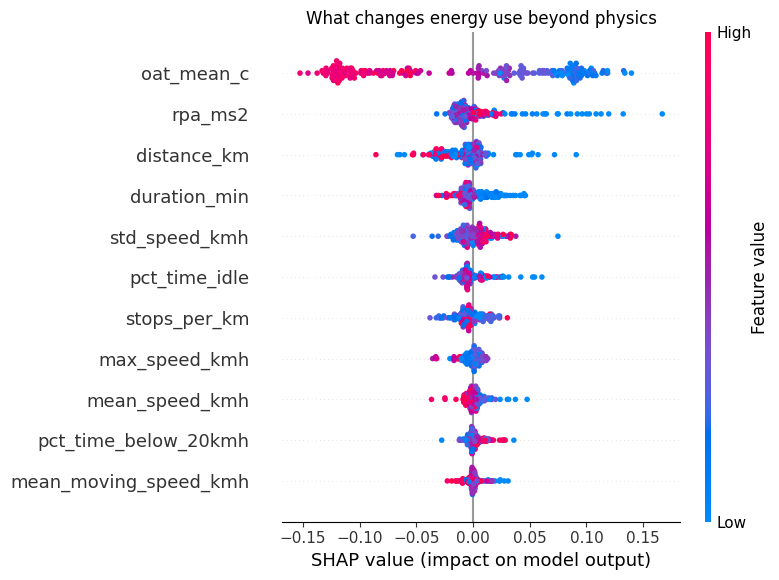

In [52]:
explainer = shap.TreeExplainer(FINAL_MODEL)
shap_values = explainer.shap_values(X_test_hyb)
shap.summary_plot(shap_values, X_test_hyb, show=False)
plt.title("What changes energy use beyond physics"); plt.tight_layout(); plt.show()

**EV AND MIDC RANGE**

In [53]:
VEHICLE = {
    "name": "Example compact EV (replace with your car)",
    "kerb_mass_kg": 1500,
    "battery_kwh": 40.0,
    "usable_fraction": 0.92,
    "Cd": 0.33,
    "frontal_area_m2": 2.3,
    "Crr": PHYS["Crr"],
    "certified_range_km": None,
}

def simulate_drive(speed_kmh, veh, T_amb, payload_kg=DRIVER_KG, use_climate=True):
    """Physics Wh/km for any second-by-second speed list."""
    v = np.asarray(speed_kmh, dtype=float) / 3.6
    a = np.clip(np.gradient(pd.Series(v).rolling(3, center=True, min_periods=1).mean().values), -4, 4)
    m = veh["kerb_mass_kg"] + payload_kg
    rho = 101325 / (287.05 * (T_amb + 273.15))
    force = m * 9.81 * veh["Crr"] + 0.5 * rho * veh["Cd"] * veh["frontal_area_m2"] * v ** 2 + 1.05 * m * a
    wheel = np.where(v <= 0.05, 0, force * v)
    batt = np.where(wheel >= 0, wheel / PHYS["eta_drive"], wheel * PHYS["eta_regen"]) + PHYS["aux_w"]
    if use_climate:
        batt = batt + climate_power_w(T_amb)
    km = v.sum() / 1000
    return batt.sum() / 3600 / km, km

def usable_kwh(veh):
    return veh["battery_kwh"] * veh["usable_fraction"]

whkm_midc, km_midc = simulate_drive(midc.speed_kmh, VEHICLE, T_amb=25, use_climate=False)
RANGE_MIDC = usable_kwh(VEHICLE) * 1000 / whkm_midc
print(f"MIDC: {km_midc:.2f} km per test, {whkm_midc:.1f} Wh/km → brochure-style range ≈ {RANGE_MIDC:.0f} km")
if VEHICLE["certified_range_km"]:
    print(f"Brochure says {VEHICLE['certified_range_km']} km → our model is {100*(RANGE_MIDC/VEHICLE['certified_range_km']-1):+.1f}% different")

MIDC: 10.33 km per test, 107.4 Wh/km → brochure-style range ≈ 343 km


In [54]:
BANDS = {"peak": (15, 22), "offpeak": (22, 32), "night": (32, 45)}

def band_of(hour):
    if 8 <= hour < 11 or 17 <= hour < 21:
        return "peak"
    if hour >= 21 or hour < 6:
        return "night"
    return "offpeak"

def build_drive(lo, hi, target_seconds=1800):
    pool = trips[(trips.mean_speed_kmh >= lo) & (trips.mean_speed_kmh < hi)][["VehId", "Trip"]]
    order = np.random.default_rng(RANDOM_STATE).permutation(len(pool))
    pieces, total = [], 0
    for i in order:
        veh_id, trip_id = pool.iloc[i]
        s = traces[(traces.VehId == veh_id) & (traces.Trip == trip_id)].speed_kmh.values
        pieces.append(s); total += len(s)
        if total >= target_seconds:
            break
    return np.concatenate(pieces)

def drive_features(speed_kmh):
    v = np.asarray(speed_kmh, dtype=float)
    a = np.gradient(v / 3.6)
    seconds, km = len(v), v.sum() / 3600
    stops = np.sum((v[:-1] > 0) & (v[1:] == 0))
    return {"distance_km": km, "duration_min": seconds / 60, "mean_speed_kmh": km / (seconds / 3600),
            "mean_moving_speed_kmh": v[v > 0].mean(), "std_speed_kmh": v.std(), "max_speed_kmh": v.max(),
            "pct_time_idle": np.mean(v == 0) * 100, "pct_time_below_20kmh": np.mean(v < 20) * 100,
            "stops_per_km": stops / km, "rpa_ms2": np.sum(v / 3.6 * np.clip(a, 0, None)) / (km * 1000)}

delhi_drives = {band: build_drive(*BANDS[band]) for band in BANDS}
delhi_feats = {band: drive_features(d) for band, d in delhi_drives.items()}
pd.DataFrame(delhi_feats).T[["distance_km", "duration_min", "mean_speed_kmh", "pct_time_idle", "stops_per_km"]].round(2)

,distance_km,duration_min,mean_speed_kmh,pct_time_idle,stops_per_km
peak,21.25,67.42,18.91,34.22,2.16
offpeak,16.64,36.47,27.38,23.86,1.38
night,20.20,32.33,37.49,23.25,0.40


In [55]:
def predict_range(speed_kmh, veh, T_amb, payload_kg=DRIVER_KG, feats=None):
    phys_whkm, _ = simulate_drive(speed_kmh, veh, T_amb, payload_kg)
    f = dict(feats or drive_features(speed_kmh))
    f["oat_mean_c"] = T_amb
    X = pd.DataFrame([f])[FEATURES]
    whkm = phys_whkm * float(np.exp(FINAL_MODEL.predict(X)[0]))
    return {"physics_wh_per_km": phys_whkm, "wh_per_km": whkm,
            "range_km": usable_kwh(veh) * 1000 / whkm}

example = predict_range(delhi_drives["peak"], VEHICLE, T_amb=40, feats=delhi_feats["peak"])
print(f"July rush hour, 40°C: {example['range_km']:.0f} km  ({example['wh_per_km']:.0f} Wh/km)")
print(f"Brochure-style MIDC range: {RANGE_MIDC:.0f} km")

July rush hour, 40°C: 214 km  (172 Wh/km)
Brochure-style MIDC range: 343 km


**DELHI RANGE ALTAS**

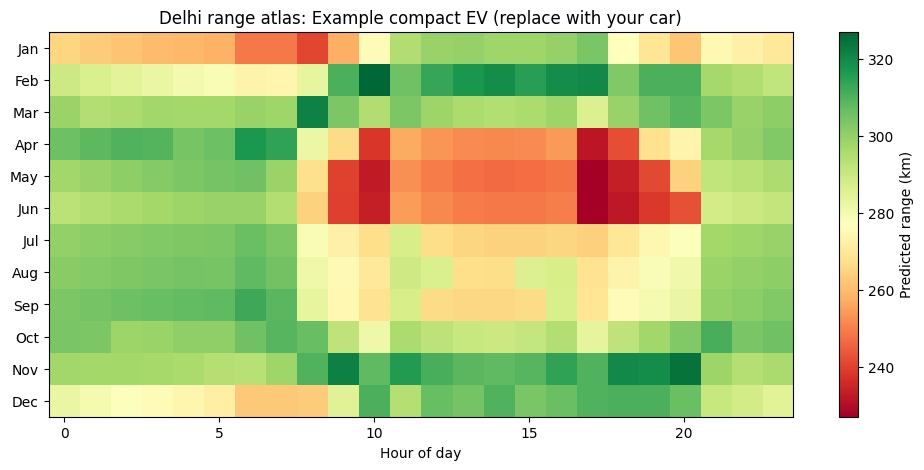

Brochure-style (MIDC) range: 343 km
Best : Feb 10:00, 19°C, peak → 327 km (-5% vs MIDC)
Worst: Jun 17:00, 36°C, peak → 227 km (-34% vs MIDC)


In [56]:
atlas_rows = []
for month in range(1, 13):
    for hour in range(24):
        band = band_of(hour)
        T = float(delhi_temp.loc[month, hour])
        p = predict_range(delhi_drives[band], VEHICLE, T, feats=delhi_feats[band])
        atlas_rows.append({"month": month, "hour": hour, "traffic": band, "temp_c": T, **p})
atlas = pd.DataFrame(atlas_rows)

plt.figure(figsize=(12, 5))
plt.imshow(atlas.pivot(index="month", columns="hour", values="range_km"), aspect="auto", cmap="RdYlGn")
plt.colorbar(label="Predicted range (km)")
plt.yticks(range(12), MONTHS); plt.xlabel("Hour of day")
plt.title(f"Delhi range atlas: {VEHICLE['name']}"); plt.show()

best, worst = atlas.loc[atlas.range_km.idxmax()], atlas.loc[atlas.range_km.idxmin()]
print(f"Brochure-style (MIDC) range: {RANGE_MIDC:.0f} km")
print(f"Best : {MONTHS[int(best.month)-1]} {int(best.hour):02d}:00, {best.temp_c:.0f}°C, {best.traffic} → "
      f"{best.range_km:.0f} km ({100*(best.range_km/RANGE_MIDC-1):+.0f}% vs MIDC)")
print(f"Worst: {MONTHS[int(worst.month)-1]} {int(worst.hour):02d}:00, {worst.temp_c:.0f}°C, {worst.traffic} → "
      f"{worst.range_km:.0f} km ({100*(worst.range_km/RANGE_MIDC-1):+.0f}% vs MIDC)")

**SENSITIVITY CHECK**

In [57]:
base_range = predict_range(delhi_drives[worst.traffic], VEHICLE, worst.temp_c)["range_km"]
rows = []
for key in ["Cd", "frontal_area_m2", "Crr", "kerb_mass_kg"]:
    for factor in [0.9, 1.1]:
        changed = dict(VEHICLE); changed[key] = VEHICLE[key] * factor
        r = predict_range(delhi_drives[worst.traffic], changed, worst.temp_c)["range_km"]
        rows.append({"what we changed": key, "by": f"{(factor-1)*100:+.0f}%", "range_km": r})
original_ac_k = AC_K
for factor in [0.8, 1.2]:
    AC_K = original_ac_k * factor
    r = predict_range(delhi_drives[worst.traffic], VEHICLE, worst.temp_c)["range_km"]
    rows.append({"what we changed": "AC power per °C", "by": f"{(factor-1)*100:+.0f}%", "range_km": r})
AC_K = original_ac_k
sensitivity = pd.DataFrame(rows)
sensitivity["range change %"] = 100 * (sensitivity.range_km / base_range - 1)
print(f"Worst-case range with our best guesses: {base_range:.0f} km")
sensitivity.round(1)

Worst-case range with our best guesses: 227 km


,what we changed,by,range_km,range change %
0,Cd,-10%,229.4,1.0
1,Cd,+10%,225.0,-1.0
2,frontal_area_m2,-10%,229.4,1.0
3,frontal_area_m2,+10%,225.0,-1.0
4,Crr,-10%,235.8,3.8
5,Crr,+10%,219.1,-3.5
6,kerb_mass_kg,-10%,238.5,5.0
7,kerb_mass_kg,+10%,216.8,-4.6
8,AC power per °C,-20%,242.9,6.9
9,AC power per °C,+20%,213.3,-6.1


In [58]:
# Models
joblib.dump({
    "linear_regression": lr,
    "rf_default": rf_default, "rf_tuned": rf_tuned,
    "xgb_default": xgb_default, "xgb_tuned": xgb_tuned,
    "hybrid_rf_default": hrf_default, "hybrid_rf_tuned": hrf_tuned,
    "hybrid_xgb_default": hxgb_default, "hybrid_xgb_tuned": hxgb_tuned,
    "final_model": FINAL_MODEL,
}, os.path.join(OUT_DIR, "models.joblib"))

with open(os.path.join(OUT_DIR, "best_hyperparameters.json"), "w") as fh:
    json.dump({"random_forest": rf_search.best_params_, "xgboost": xgb_search.best_params_,
               "hybrid_rf": hrf_search.best_params_, "hybrid_xgboost": hxgb_search.best_params_},
              fh, indent=2, default=str)

with open(os.path.join(OUT_DIR, "model_config.json"), "w") as fh:
    json.dump({"final_model": FINAL_NAME, "features": FEATURES, "pure_features": PURE_FEATURES,
               "physics_params": PHYS,
               "climate_rule": {"AC_C0": float(AC_C0), "AC_K": float(AC_K), "HEAT_K": float(HEAT_K)},
               "vehicle": VEHICLE, "driver_kg": DRIVER_KG}, fh, indent=2)

# Tables: save each one if it exists, otherwise say which step creates it
tables = [
    ("results",       "results_all_models.csv",                "Step 14–17", True),
    ("after",         "results_after_tuning.csv",              "Step 17f",   True),
    ("best_settings", "best_settings_table.csv",               "Step 17f",   True),
    ("compare",       "before_vs_after_tuning.csv",            "Step 18a",   True),
    ("cv_table",      "cross_validation.csv",                  "Step 19",    True),
    ("cv_compare",    "cross_validation_before_vs_after.csv",  "Step 19",    True),
    ("atlas",         "delhi_range_atlas.csv",                 "Step 25",    False),
    ("sensitivity",   "sensitivity.csv",                       "Step 26",    False),
]
for name, filename, step, keep_index in tables:
    if name in globals():
        pd.DataFrame(globals()[name]).round(3).to_csv(os.path.join(OUT_DIR, filename), index=keep_index)
        print(f"✅ saved {filename}")
    else:
        print(f"⚠️ skipped {filename}: run {step} first, then run this cell again")

print("\nFiles in outputs folder:", sorted(os.listdir(OUT_DIR)))


✅ saved results_all_models.csv
✅ saved results_after_tuning.csv
✅ saved best_settings_table.csv
✅ saved before_vs_after_tuning.csv
✅ saved cross_validation.csv
✅ saved cross_validation_before_vs_after.csv
✅ saved delhi_range_atlas.csv
✅ saved sensitivity.csv

Files in outputs folder: ['before_vs_after_tuning.csv', 'best_hyperparameters.json', 'best_settings_table.csv', 'cross_validation.csv', 'cross_validation_before_vs_after.csv', 'delhi_range_atlas.csv', 'model_config.json', 'models.joblib', 'results_after_tuning.csv', 'results_all_models.csv', 'sensitivity.csv']
